In [1]:
from collections import Counter
from pathlib import Path
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11})

COLOR_HUMAN = '#2878B5'
COLOR_AI = '#D9534F'
PALETTE = {'Human': COLOR_HUMAN, 'AI': COLOR_AI}
RANDOM_STATE = 42
print('Đã nạp thư viện.')

Đã nạp thư viện.


## 1. Đọc dữ liệu theo chunk và lấy mẫu phân tầng

Lần đọc đầu kiểm tra toàn bộ CSV và đếm nhãn. Lần đọc thứ hai lấy một mẫu xấp xỉ phân tầng; `SAMPLE_SIZE = 60_000` đủ cho EDA mà không cần nạp toàn bộ data vào RAM.

In [6]:
import pandas as pd

df = pd.read_csv("AI_Human.csv", nrows=5)

print("Tên các cột:")
print(df.columns.tolist())

print("\nDữ liệu mẫu:")
print(df.head())

Tên các cột:
['text', 'generated']

Dữ liệu mẫu:
                                                text  generated
0  Cars. Cars have been around since they became ...        0.0
1  Transportation is a large necessity in most co...        0.0
2  "America's love affair with it's vehicles seem...        0.0
3  How often do you ride in a car? Do you drive a...        0.0
4  Cars are a wonderful thing. They are perhaps o...        0.0


In [7]:



def valid_rows(chunk):
    text = chunk['text'].astype('string')
    label = pd.to_numeric(chunk['generated'], errors='coerce')
    mask = text.notna() & text.str.strip().str.len().gt(10) & label.isin([0, 1])
    return pd.DataFrame({'text': text[mask].str.strip(), 'generated': label[mask].astype('int8')})



def inspect_and_sample(path, sample_size=60_000, chunksize=50_000, seed=42):
    counts = Counter()
    audit = Counter()

    # Pass 1: Đếm số bản ghi hợp lệ của từng lớp
    for chunk in pd.read_csv(
        path,
        usecols=['text', 'generated'],
        chunksize=chunksize
    ):
        audit['raw_rows'] += len(chunk)

        text = chunk['text'].astype('string')
        label = pd.to_numeric(chunk['generated'], errors='coerce')

        audit['missing_text'] += int(text.isna().sum())
        audit['short_text'] += int(
            (text.notna() & text.str.strip().str.len().le(10)).sum()
        )
        audit['invalid_label'] += int((~label.isin([0, 1])).sum())

        clean = valid_rows(chunk)
        counts.update(clean['generated'].astype(int).tolist())

    if not counts:
        raise ValueError('Không có bản ghi hợp lệ với nhãn 0 hoặc 1.')

    total = sum(counts.values())
    audit['valid_rows'] = total

    # Xác định số mẫu mục tiêu cho từng lớp
    if sample_size is None:
        targets = dict(counts)
    else:
        n_target = min(int(sample_size), total)
        targets = {
            label: int(n_target * count / total)
            for label, count in counts.items()
        }

        # Phân bổ phần mẫu còn thiếu do làm tròn
        remainder = n_target - sum(targets.values())
        for label in sorted(counts, key=lambda x: counts[x], reverse=True):
            if remainder <= 0:
                break
            if targets[label] < counts[label]:
                targets[label] += 1
                remainder -= 1

    # Pass 2: Lấy mẫu ngẫu nhiên từ từng chunk
    parts = []

    for i, chunk in enumerate(pd.read_csv(
        path,
        usecols=['text', 'generated'],
        chunksize=chunksize
    )):
        clean = valid_rows(chunk)

        for label, target in targets.items():
            if target == 0:
                continue

            group = clean[clean['generated'] == label]

            if group.empty:
                continue

            n = min(
                len(group),
                max(1, int(np.ceil(target * len(group) / counts[label])))
            )

            parts.append(
                group.sample(
                    n=n,
                    random_state=seed + i * 10 + int(label)
                )
            )

    if not parts:
        raise ValueError('Không lấy được bản ghi hợp lệ.')

    sample = pd.concat(parts, ignore_index=True)

    # Giới hạn chính xác số lượng mẫu từng lớp, không dùng groupby().apply()
    final_parts = []

    for label, target in targets.items():
        group = sample[sample['generated'] == label]

        if len(group) < target:
            raise ValueError(
                f'Không đủ mẫu lớp {label}: cần {target}, '
                f'nhưng chỉ lấy được {len(group)}.'
            )

        if target > 0:
            final_parts.append(
                group.sample(n=target, random_state=seed + int(label))
            )

    sample = pd.concat(final_parts, ignore_index=True)
    sample = sample.sample(frac=1, random_state=seed).reset_index(drop=True)

    # Tạo nhãn phân loại
    sample['label'] = sample['generated'].map({
        0: 'Human',
        1: 'AI'
    })

    return sample, dict(audit), dict(counts)



DATA_PATH = Path(r"D:\Project SamSung\AI-gen-text-detection\data\AI_Human.csv")
SAMPLE_SIZE = 60_000
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy data/AI_Human.csv.')

started = time.perf_counter()
df, audit, class_counts = inspect_and_sample(DATA_PATH, SAMPLE_SIZE, seed=RANDOM_STATE)
print('Đã đọc {:,} dòng và lấy mẫu {:,} dòng trong {:.1f} giây.'.format(audit['raw_rows'], len(df), time.perf_counter() - started))
print('Data path:', DATA_PATH.resolve())

Đã đọc 487,235 dòng và lấy mẫu 60,000 dòng trong 17.5 giây.
Data path: D:\Project SamSung\AI-gen-text-detection\data\AI_Human.csv


## 2. Chất lượng dữ liệu và phân bố nhãn

Chất lượng được đo trên toàn bộ CSV. Exact duplicate chỉ kiểm tra trong mẫu để tránh giữ gần 500.000 chuỗi dài trong RAM. Biểu đồ cột thay cho donut vì hiển thị số lượng và chênh lệch lớp rõ hơn.

,Chỉ số,Giá trị
0,Tổng dòng CSV,487235
1,Dòng hợp lệ,487229
2,Text thiếu,0
3,Text quá ngắn (<=10 ký tự),6
4,Nhãn không hợp lệ,0
5,Duplicate text trong mẫu,308


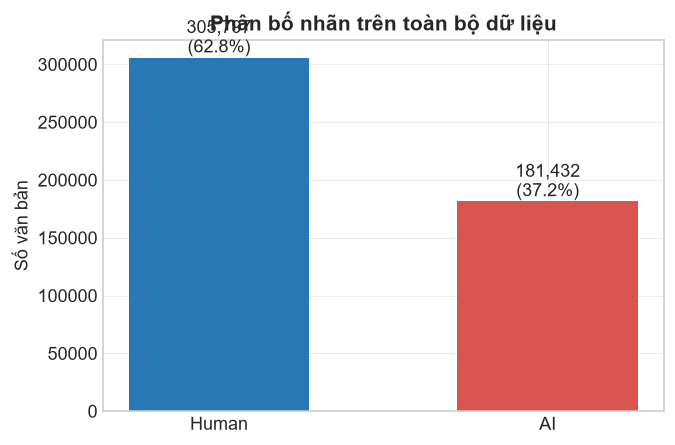

Phân bố nhãn trong mẫu EDA:


,label,sample_count
0,Human,37658
1,AI,22342


In [8]:
full_counts = pd.Series(class_counts).sort_index()
full_counts.index = full_counts.index.map({0: 'Human', 1: 'AI'})

overview = pd.DataFrame({
    'Chỉ số': ['Tổng dòng CSV', 'Dòng hợp lệ', 'Text thiếu', 'Text quá ngắn (<=10 ký tự)', 'Nhãn không hợp lệ', 'Duplicate text trong mẫu'],
    'Giá trị': [audit['raw_rows'], audit['valid_rows'], audit['missing_text'], audit['short_text'], audit['invalid_label'], int(df['text'].duplicated().sum())],
})
display(overview)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(full_counts.index, full_counts.values, color=[PALETTE[x] for x in full_counts.index], width=0.55)
ax.set_title('Phân bố nhãn trên toàn bộ dữ liệu', fontweight='bold')
ax.set_ylabel('Số văn bản')
for bar, n in zip(bars, full_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), '{:,}\n({:.1%})'.format(n, n / full_counts.sum()), ha='center', va='bottom')
plt.tight_layout()
plt.show()

print('Phân bố nhãn trong mẫu EDA:')
display(df['label'].value_counts().rename_axis('label').reset_index(name='sample_count'))

## 3. Trích xuất đặc trưng

`avg_word_len` chỉ dùng số chữ cái thay vì tính cả khoảng trắng và dấu câu. `root_ttr` là lexical diversity được hiệu chỉnh phần nào theo độ dài, đáng tin cậy hơn Type-Token Ratio thô khi độ dài bài viết không đồng đều.**

In [9]:
def lexical_stats(text):
    tokens = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text.lower())
    n_tokens = max(len(tokens), 1)
    unique = len(set(tokens))
    return unique, unique / n_tokens, unique / np.sqrt(n_tokens)


started = time.perf_counter()
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.count(r'\S+')
df['letter_count'] = df['text'].str.count(r'[A-Za-z]')
df['sentence_count'] = df['text'].str.count(r'[.!?]+').clip(lower=1)
df['avg_word_len'] = df['letter_count'] / df['word_count'].clip(lower=1)
df['avg_sentence_len'] = df['word_count'] / df['sentence_count']
df['punct_density'] = df['text'].str.count(r'[^\w\s]') / df['word_count'].clip(lower=1) * 100
df['uppercase_ratio'] = df['text'].str.count(r'[A-Z]') / df['letter_count'].clip(lower=1) * 100
df['digit_density'] = df['text'].str.count(r'\d') / df['char_count'].clip(lower=1) * 100
df['newline_density'] = df['text'].str.count(r'\n') / df['word_count'].clip(lower=1) * 100
df[['unique_word_count', 'type_token_ratio', 'root_ttr']] = pd.DataFrame(df['text'].map(lexical_stats).tolist(), index=df.index)
print('Đã trích xuất đặc trưng trong {:.1f} giây.'.format(time.perf_counter() - started))

Đã trích xuất đặc trưng trong 16.8 giây.


## 4. Độ dài văn bản: biến gây nhiễu cần kiểm soát

Nếu hai lớp khác nhau về độ dài, mô hình có thể dự đoán dựa vào độ dài thay vì phong cách. ECDF cho toàn bộ phân bố; biểu đồ cột cho biết tỷ lệ AI ở các nhóm độ dài có cùng số lượng mẫu.

In [ ]:
length_df = df[df['word_count'].between(1, df['word_count'].quantile(0.995))].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.ecdfplot(data=length_df, x='word_count', hue='label', palette=PALETTE, linewidth=2, ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title('ECDF số từ theo nhãn', fontweight='bold')
axes[0].set_xlabel('Số từ (thang log; cắt 0.5% ngoại lai)')
axes[0].set_ylabel('Tỷ lệ tích lũy')

length_df['length_group'] = pd.qcut(length_df['word_count'], q=6, duplicates='drop')
ai_rate = length_df.groupby('length_group', observed=True)['generated'].mean().mul(100)
ai_rate.plot(kind='bar', color=COLOR_AI, width=0.7, ax=axes[1])
axes[1].axhline(full_counts['AI'] / full_counts.sum() * 100, color='black', linestyle='--', label='Tỷ lệ AI toàn bộ')
axes[1].set_title('Tỷ lệ AI theo nhóm độ dài', fontweight='bold')
axes[1].set_xlabel('Nhóm quantile của số từ')
axes[1].set_ylabel('AI (%)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Xếp hạng stylometric features

Cohen's d xếp hạng độ lớn khác biệt đơn biến giữa AI và Human, dễ dùng hơn một heatmap tương quan dày đặc. Đây là mô tả dữ liệu, không phải bằng chứng nhân quả.

In [ ]:
style_features = ['word_count', 'avg_word_len', 'avg_sentence_len', 'root_ttr', 'punct_density', 'uppercase_ratio', 'digit_density', 'newline_density']
human = df[df['generated'] == 0]
ai = df[df['generated'] == 1]

def cohens_d(ai_values, human_values):
    pooled_std = np.sqrt((ai_values.var(ddof=1) + human_values.var(ddof=1)) / 2)
    return 0.0 if pooled_std == 0 else (ai_values.mean() - human_values.mean()) / pooled_std

effect_table = pd.DataFrame({
    'feature': style_features,
    'human_median': [human[x].median() for x in style_features],
    'ai_median': [ai[x].median() for x in style_features],
    'cohens_d_ai_minus_human': [cohens_d(ai[x], human[x]) for x in style_features],
}).sort_values('cohens_d_ai_minus_human')
display(effect_table.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
colors = np.where(effect_table['cohens_d_ai_minus_human'] >= 0, COLOR_AI, COLOR_HUMAN)
ax.barh(effect_table['feature'], effect_table['cohens_d_ai_minus_human'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title("Khác biệt chuẩn hóa: AI trừ Human (Cohen's d)", fontweight='bold')
ax.set_xlabel("Cohen's d")
plt.tight_layout()
plt.show()

## 6. Stylometry khi đã hạn chế ảnh hưởng độ dài

Chỉ lấy các văn bản có số từ trong khoảng phần tư thứ nhất đến thứ ba, rồi cân bằng số mẫu hai lớp. Nếu khác biệt vẫn hiện diện, feature có khả năng hữu ích ngoài biến độ dài.

In [ ]:
low_words, high_words = df['word_count'].quantile([0.25, 0.75])
matched = df[df['word_count'].between(low_words, high_words)].copy()
matched_n = min(matched['label'].value_counts().min(), 10_000)
matched = matched.groupby('label', group_keys=False).sample(n=matched_n, random_state=RANDOM_STATE)

features_to_plot = ['avg_word_len', 'root_ttr', 'punct_density', 'uppercase_ratio']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for feature, ax in zip(features_to_plot, axes.ravel()):
    upper = matched[feature].quantile(0.99)
    sns.kdeplot(data=matched[matched[feature] <= upper], x=feature, hue='label', common_norm=False, fill=True, alpha=0.25, palette=PALETTE, ax=ax)
    ax.set_title(feature + ' khi độ dài được kiểm soát', fontweight='bold')
plt.suptitle('Mẫu cân bằng: {:,} văn bản mỗi lớp, {:.0f}–{:.0f} từ'.format(matched_n, low_words, high_words), y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Word n-grams có tính phân biệt

Không dùng raw count vì lớp Human lớn hơn. Hai lớp được cân bằng trước, sau đó n-grams được xếp hạng theo chênh lệch TF-IDF trung bình. Đây là trực quan hóa liên quan trực tiếp đến Pipeline Word TF-IDF.

In [ ]:
ngram_n = min(df['label'].value_counts().min(), 12_000)
ngram_df = df.groupby('label', group_keys=False).sample(n=ngram_n, random_state=RANDOM_STATE).reset_index(drop=True)

vectorizer = TfidfVectorizer(
    lowercase=True, stop_words='english', ngram_range=(1, 2),
    min_df=5, max_df=0.90, sublinear_tf=True, max_features=60_000
)
X = vectorizer.fit_transform(ngram_df['text'])
terms = vectorizer.get_feature_names_out()
mean_ai = np.asarray(X[ngram_df['generated'].eq(1)].mean(axis=0)).ravel()
mean_human = np.asarray(X[ngram_df['generated'].eq(0)].mean(axis=0)).ravel()
term_scores = pd.DataFrame({'term': terms, 'ai_minus_human_tfidf': mean_ai - mean_human})
top_human = term_scores.nsmallest(12, 'ai_minus_human_tfidf').sort_values('ai_minus_human_tfidf')
top_ai = term_scores.nlargest(12, 'ai_minus_human_tfidf').sort_values('ai_minus_human_tfidf')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top_human['term'], -top_human['ai_minus_human_tfidf'], color=COLOR_HUMAN)
axes[0].set_title('N-grams đặc trưng hơn cho Human', fontweight='bold')
axes[0].set_xlabel('Chênh lệch TF-IDF trung bình')
axes[1].barh(top_ai['term'], top_ai['ai_minus_human_tfidf'], color=COLOR_AI)
axes[1].set_title('N-grams đặc trưng hơn cho AI', fontweight='bold')
axes[1].set_xlabel('Chênh lệch TF-IDF trung bình')
plt.tight_layout()
plt.show()

display(pd.concat([top_human.assign(class_hint='Human'), top_ai.assign(class_hint='AI')], ignore_index=True))

## 8. Kiểm tra định tính và định hướng modelling

Các ví dụ chỉ để đọc cảm quan; không dùng chúng làm kết luận. Chọn feature dựa trên biểu đồ và kiểm chứng cuối cùng bằng cross-validation/test tách riêng.

In [ ]:
examples = (
    df.groupby('label', group_keys=False).sample(n=1, random_state=123)
    [['label', 'word_count', 'avg_word_len', 'punct_density', 'text']]
    .assign(text=lambda x: x['text'].str.slice(0, 700) + '...')
    .reset_index(drop=True)
)
display(examples)

strongest = effect_table.loc[effect_table['cohens_d_ai_minus_human'].abs().idxmax()]
print('Tóm tắt sau khi chạy notebook:')
print('- Feature đơn biến khác biệt nhất: {} (d = {:.2f}).'.format(strongest['feature'], strongest['cohens_d_ai_minus_human']))
print('- Pipeline 1: Word TF-IDF + linear model làm baseline.')
print('- Pipeline 2: thêm Character TF-IDF để bắt dấu câu, chính tả và cấu trúc bề mặt.')
print('- Pipeline 3: chỉ giữ stylometry features còn khác biệt sau kiểm soát độ dài.')
print('- Không được coi độ dài hoặc n-gram là bằng chứng chắc chắn AI; cần test tách riêng và dữ liệu ngoài nguồn.')